# 01 · Exploratory Data Analysis (EDA)

**Goal.** Understand the diabetes dataset before any modelling: check its quality, look at the distribution of each variable, and see which variables are related to the target.
**Sections:** 1. Load the data · 2. Data quality · 3. Target variable · 4. Univariate analysis · 5. Bivariate analysis · 6. Correlations

In [1]:
# Imports and plotting theme
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
# Load the raw CSV (the path is relative to the notebooks/ folder)
df = pd.read_csv("../data/raw/diabetes_dataset.csv")
df.head()

,Patient_ID,Age,Gender,BMI,Glucose_Level,Blood_Pressure,Insulin,Physical_Activity,Family_History,Diabetes_Outcome
0,P0001,58,F,36.4,151,102,98.5,86,Yes,1
1,P0002,71,M,28.3,185,80,294.3,29,No,0
2,P0003,48,M,27.1,172,82,186.5,108,Yes,1
3,P0004,34,F,24.0,86,139,181.0,46,No,0
4,P0005,62,M,19.2,83,106,228.2,86,Yes,0


In [3]:
# First look: number of rows and columns, column types, non-null counts
print("Dimensions :", df.shape)
df.info()

Dimensions : (500, 10)
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         500 non-null    str    
 1   Age                500 non-null    int64  
 2   Gender             500 non-null    str    
 3   BMI                500 non-null    float64
 4   Glucose_Level      500 non-null    int64  
 5   Blood_Pressure     500 non-null    int64  
 6   Insulin            500 non-null    float64
 7   Physical_Activity  500 non-null    int64  
 8   Family_History     500 non-null    str    
 9   Diabetes_Outcome   500 non-null    int64  
dtypes: float64(2), int64(5), str(3)
memory usage: 43.4 KB


## 2. Data quality and descriptive statistics
We check the summary statistics, missing values, duplicates and the categories of each qualitative variable.

In [4]:
# Descriptive statistics (count, mean, std, min, quartiles, max), transposed for readability
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,500.0,50.3960,17.335982,20.0,36.750,51.00,65.000,79.0
BMI,500.0,28.5942,6.288902,18.1,22.975,28.40,33.925,40.0
Glucose_Level,500.0,132.8980,38.211462,70.0,100.000,131.50,166.000,199.0
Blood_Pressure,500.0,106.6140,29.182121,60.0,80.000,104.00,132.000,159.0
Insulin,500.0,159.7376,81.385927,15.4,89.175,162.45,230.325,299.5
Physical_Activity,500.0,57.6640,33.912050,0.0,29.000,55.00,86.000,119.0
Diabetes_Outcome,500.0,0.5420,0.498732,0.0,0.000,1.00,1.000,1.0


In [5]:
# Missing values, duplicated rows and duplicated patient IDs
print("Valeurs manquantes :")
print(df.isna().sum())
print("\nLignes dupliquées :", df.duplicated().sum())
print("Patient_ID dupliqués :", df["Patient_ID"].duplicated().sum())

Valeurs manquantes :
Patient_ID           0
Age                  0
Gender               0
BMI                  0
Glucose_Level        0
Blood_Pressure       0
Insulin              0
Physical_Activity    0
Family_History       0
Diabetes_Outcome     0
dtype: int64

Lignes dupliquées : 0
Patient_ID dupliqués : 0


In [6]:
# Frequency of each category (Gender, Family_History) and of the target
for col in ["Gender", "Family_History", "Diabetes_Outcome"]:
    print(df[col].value_counts(), "\n")

Gender
M    252
F    248
Name: count, dtype: int64 

Family_History
Yes    296
No     204
Name: count, dtype: int64 

Diabetes_Outcome
1    271
0    229
Name: count, dtype: int64 



## 3. Target variable
Class balance matters for the choice of metrics and for deciding whether imbalance correction is needed. Here the classes are close to balanced: about 54.2% diabetic (1) and 45.8% non-diabetic (0).

Diabetes_Outcome
1    54.2
0    45.8
Name: proportion, dtype: float64


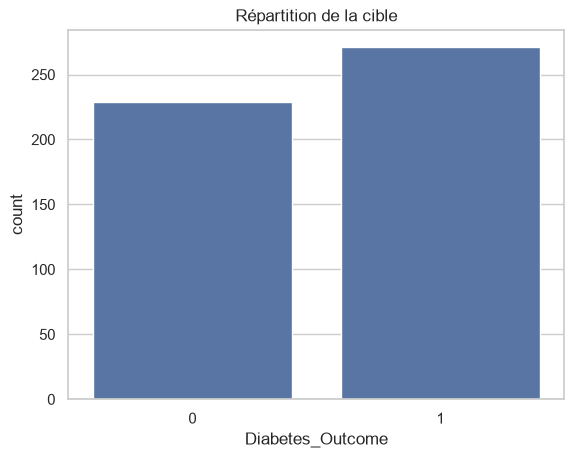

In [3]:
# Target proportions (in %) and a bar chart of the class counts
print((df["Diabetes_Outcome"].value_counts(normalize=True) * 100).round(1))

sns.countplot(data=df, x="Diabetes_Outcome")
plt.title("Répartition de la cible")
plt.show()

## 4. Univariate analysis
Each variable is studied on its own: distribution shape (histograms) and extreme values (boxplots).

In [5]:
# Feature lists reused by the plots below: numeric and categorical columns
num_cols = ["Age", "BMI", "Glucose_Level", "Blood_Pressure", "Insulin", "Physical_Activity"]
cat_cols = ["Gender", "Family_History"]

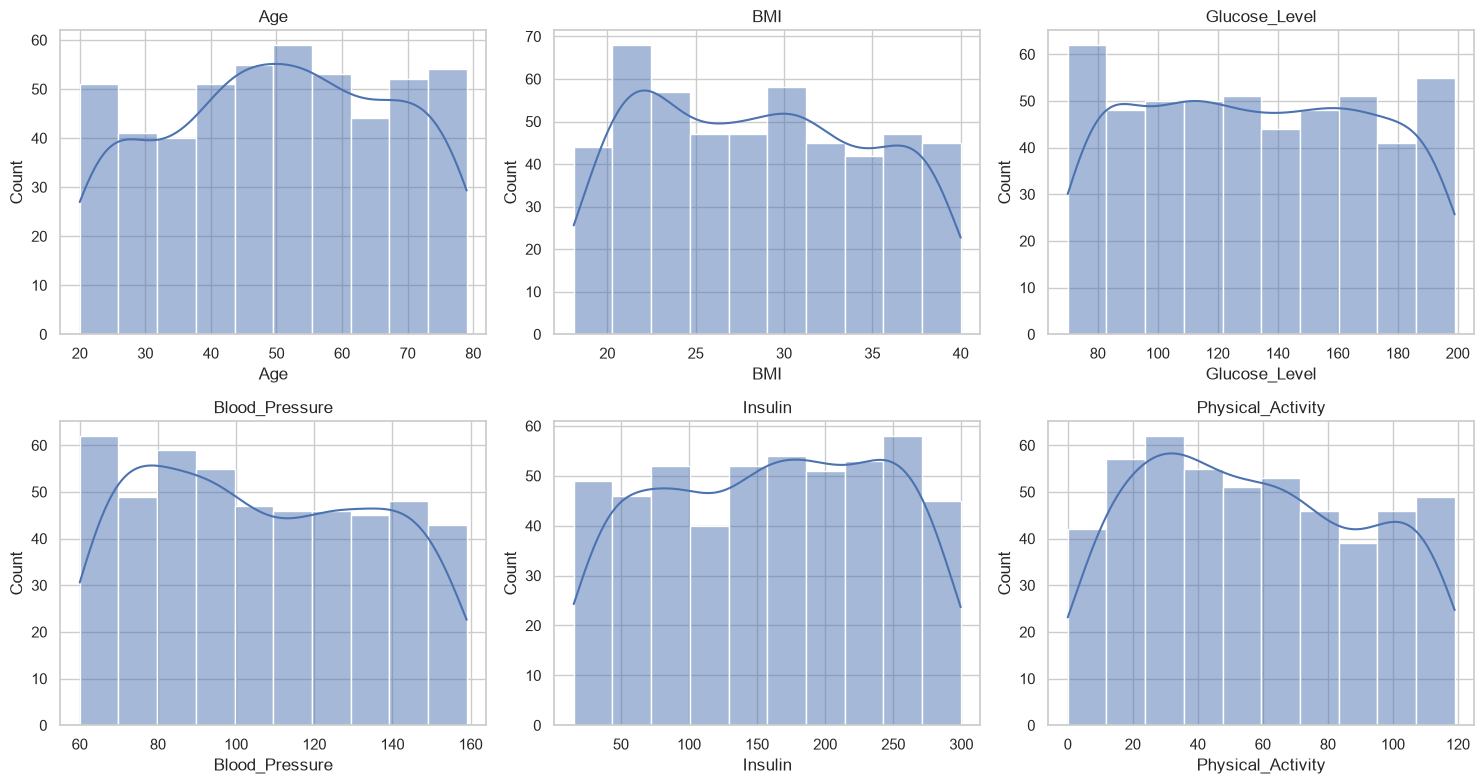

In [6]:
# Histograms with a density curve: shape of each numeric distribution
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.histplot(df[c], kde=True, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

### Outliers
A value is flagged as an outlier by the **IQR rule** if it is below `Q1 - 1.5 x IQR` or above `Q3 + 1.5 x IQR`. The dictionary printed below gives the number of outliers per variable.

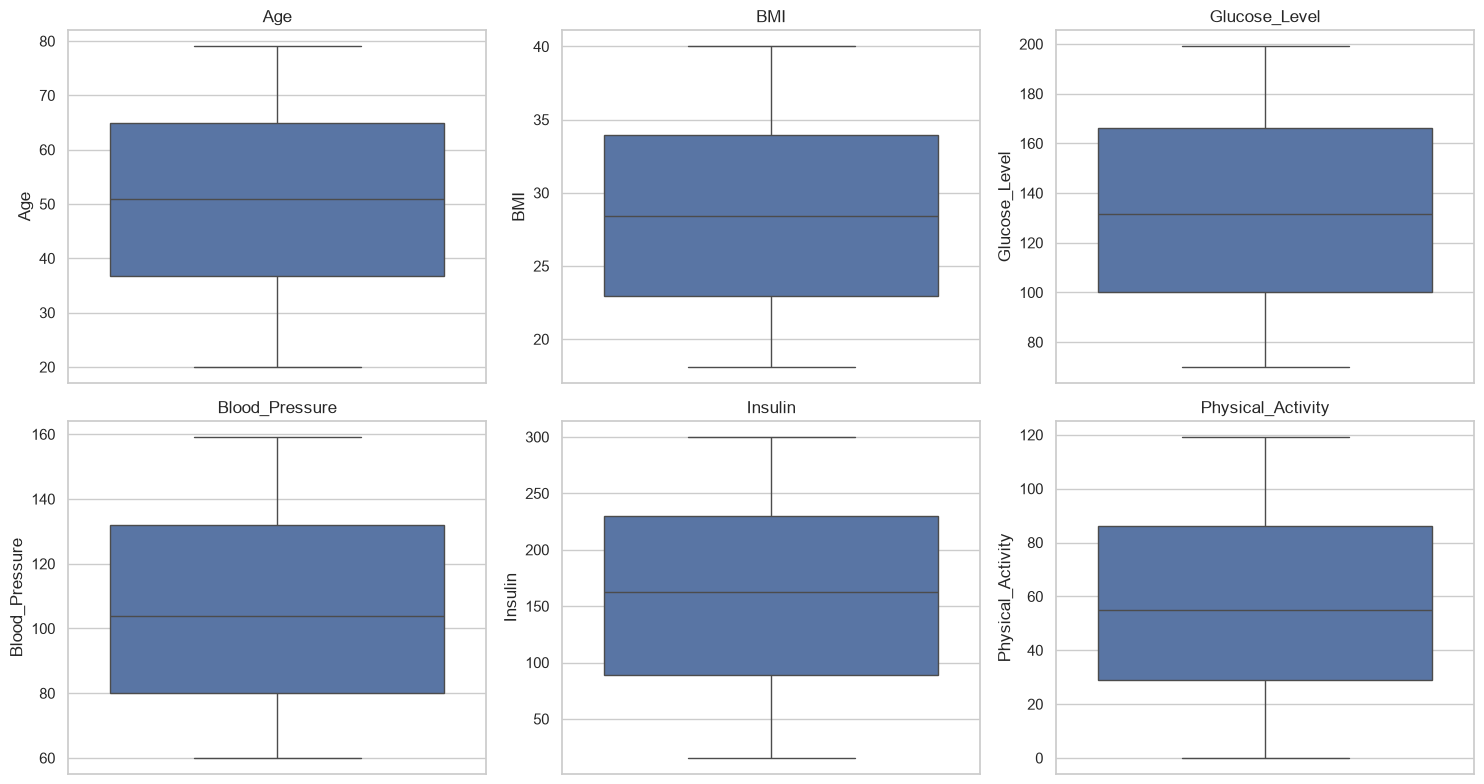

{'Age': 0, 'BMI': 0, 'Glucose_Level': 0, 'Blood_Pressure': 0, 'Insulin': 0, 'Physical_Activity': 0}


In [7]:
# Boxplots, plus a helper that counts IQR outliers per variable
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

def nb_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

print({c: int(nb_outliers(df[c])) for c in num_cols})

## 5. Bivariate analysis
Each feature is compared with the target to see which ones separate diabetic from non-diabetic patients.

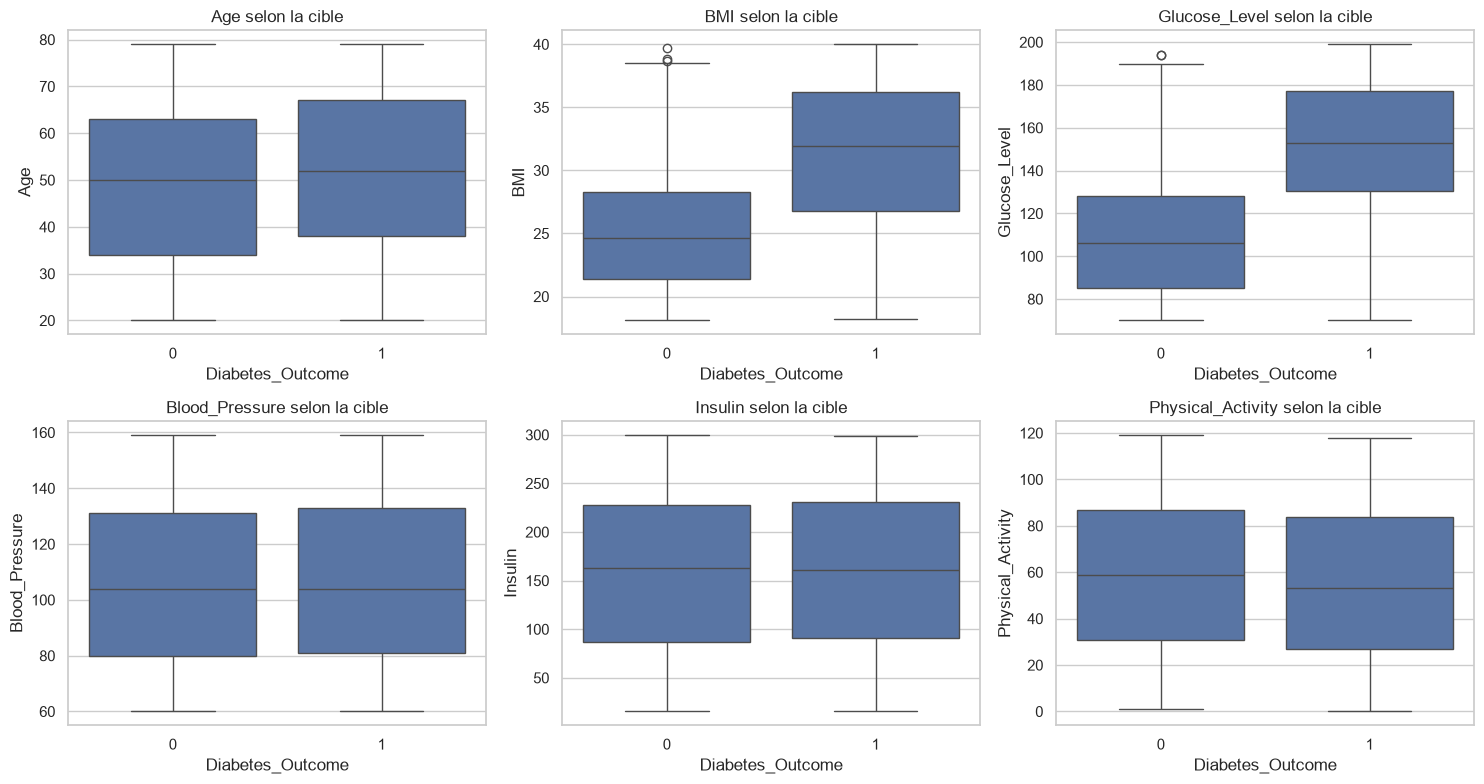

In [8]:
# Numeric features vs target: one boxplot per feature, split by Diabetes_Outcome
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="Diabetes_Outcome", y=c, ax=ax)
    ax.set_title(f"{c} selon la cible")
plt.tight_layout()
plt.show()


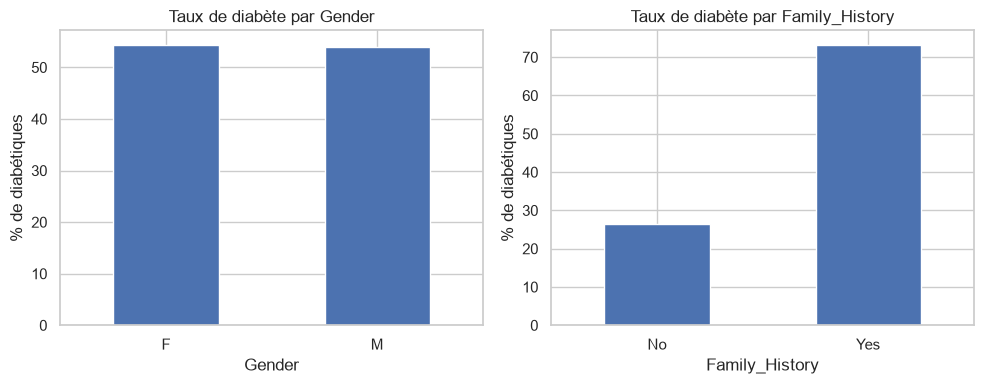

In [9]:
# Categorical features vs target: percentage of diabetic patients in each category
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, c in zip(axes, cat_cols):
    (df.groupby(c)["Diabetes_Outcome"].mean() * 100).plot(kind="bar", ax=ax, rot=0)
    ax.set_ylabel("% de diabétiques")
    ax.set_title(f"Taux de diabète par {c}")
plt.tight_layout()
plt.show()

## 6. Correlations
Categorical columns are encoded as 0/1 (`Gender`: M = 1, `Family_History`: Yes = 1) only for this heatmap. The last line lists the correlation of each variable with the target, sorted by absolute value. The strongest are `Glucose_Level`, `Family_History` and `BMI`.

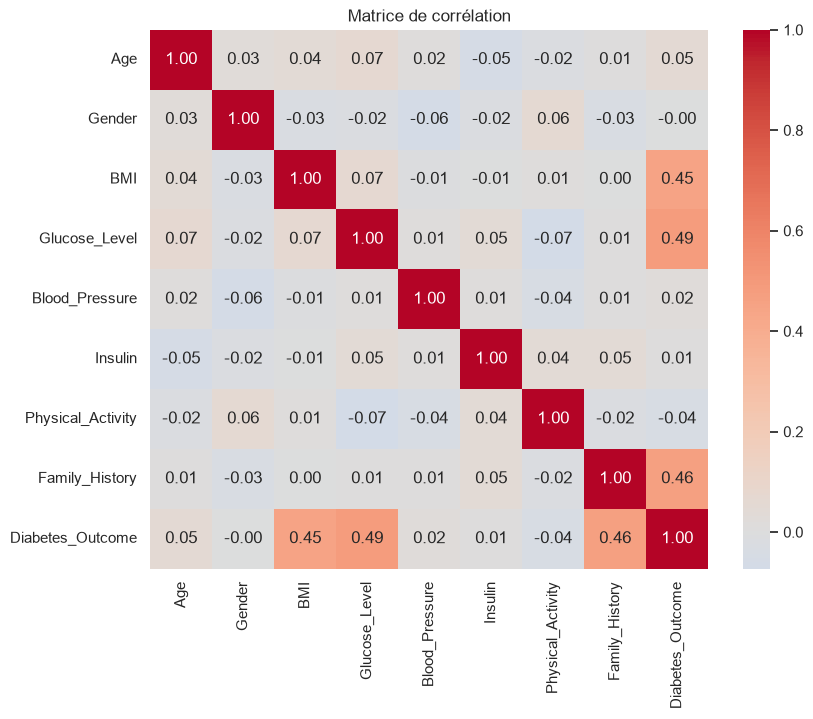

Glucose_Level        0.492098
Family_History       0.462038
BMI                  0.451965
Age                  0.049529
Physical_Activity   -0.041465
Blood_Pressure       0.021977
Insulin              0.007994
Gender              -0.004689
Name: Diabetes_Outcome, dtype: float64

In [10]:
# Encode the two categorical columns, then plot the correlation matrix
df_corr = df.drop(columns="Patient_ID").copy()
df_corr["Gender"] = (df_corr["Gender"] == "M").astype(int)
df_corr["Family_History"] = (df_corr["Family_History"] == "Yes").astype(int)

plt.figure(figsize=(9, 7))
sns.heatmap(df_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matrice de corrélation")
plt.show()

df_corr.corr()["Diabetes_Outcome"].drop("Diabetes_Outcome").sort_values(key=abs, ascending=False)

## Summary of the EDA
- **Quality:** 500 rows, no missing values, no duplicated rows.
- **Target:** almost balanced (54.2% / 45.8%), so no heavy imbalance handling is expected.
- **Outliers:** none detected with the IQR rule.
- **Most related to the target:** `Glucose_Level`, `Family_History`, `BMI`.
- **Decision for the next step:** drop `Patient_ID` (identifier with no predictive value), then split the data into train and test sets in `02_preprocessing`.